# Taxi-v3: Q-learning from scratch
Topics in AI - Assignment 1

This notebook trains, compares and evaluates a tabular agent. Run it from the project folder after installing requirements.txt. The full experiment runs nine training sessions. No pretrained RL library is used.

In [1]:
import sys
import gymnasium as gym
import numpy as np
print("Python:", sys.version.split()[0])
print("Gymnasium:", gym.__version__)
env = gym.make("Taxi-v3")
print("States:", env.observation_space.n, "Actions:", env.action_space.n)
env.close()

Python: 3.12.14
Gymnasium: 1.2.3
States: 500 Actions: 6


## Algorithm
Q(s,a) ← Q(s,a) + α[r + γ max Q(s′,a′) − Q(s,a)].
For true terminal transitions, the target is only r. Training uses epsilon-greedy exploration. Evaluation uses a greedy policy with no learning. Action masks are deliberately not used.

In [2]:
from main import run_experiments
summary = run_experiments()


Learning rate=0.01, training seed=42
Episode  1000 | exploratory return (last 100): -508.35 | greedy success: 0%
Episode  2000 | exploratory return (last 100): -298.24 | greedy success: 0%
Episode  3000 | exploratory return (last 100): -189.87 | greedy success: 5%
Episode  4000 | exploratory return (last 100): -110.54 | greedy success: 10%
Episode  5000 | exploratory return (last 100):  -65.31 | greedy success: 11%
Episode  6000 | exploratory return (last 100):  -30.76 | greedy success: 23%
Episode  7000 | exploratory return (last 100):  -20.38 | greedy success: 33%
Episode  8000 | exploratory return (last 100):  -11.32 | greedy success: 43%
Episode  9000 | exploratory return (last 100):   -2.61 | greedy success: 44%
Episode 10000 | exploratory return (last 100):    0.66 | greedy success: 53%

Learning rate=0.01, training seed=43
Episode  1000 | exploratory return (last 100): -500.13 | greedy success: 0%
Episode  2000 | exploratory return (last 100): -297.44 | greedy success: 0%
Episo

## Learning curves
Shading shows the range across three training seeds. Validation uses the same 100 starting-state seeds at each checkpoint; final testing uses 300 reset seeds in a separate evaluation run. Some test reset seeds overlap training; this measures policy performance in the same environment, not unseen-state generalization.

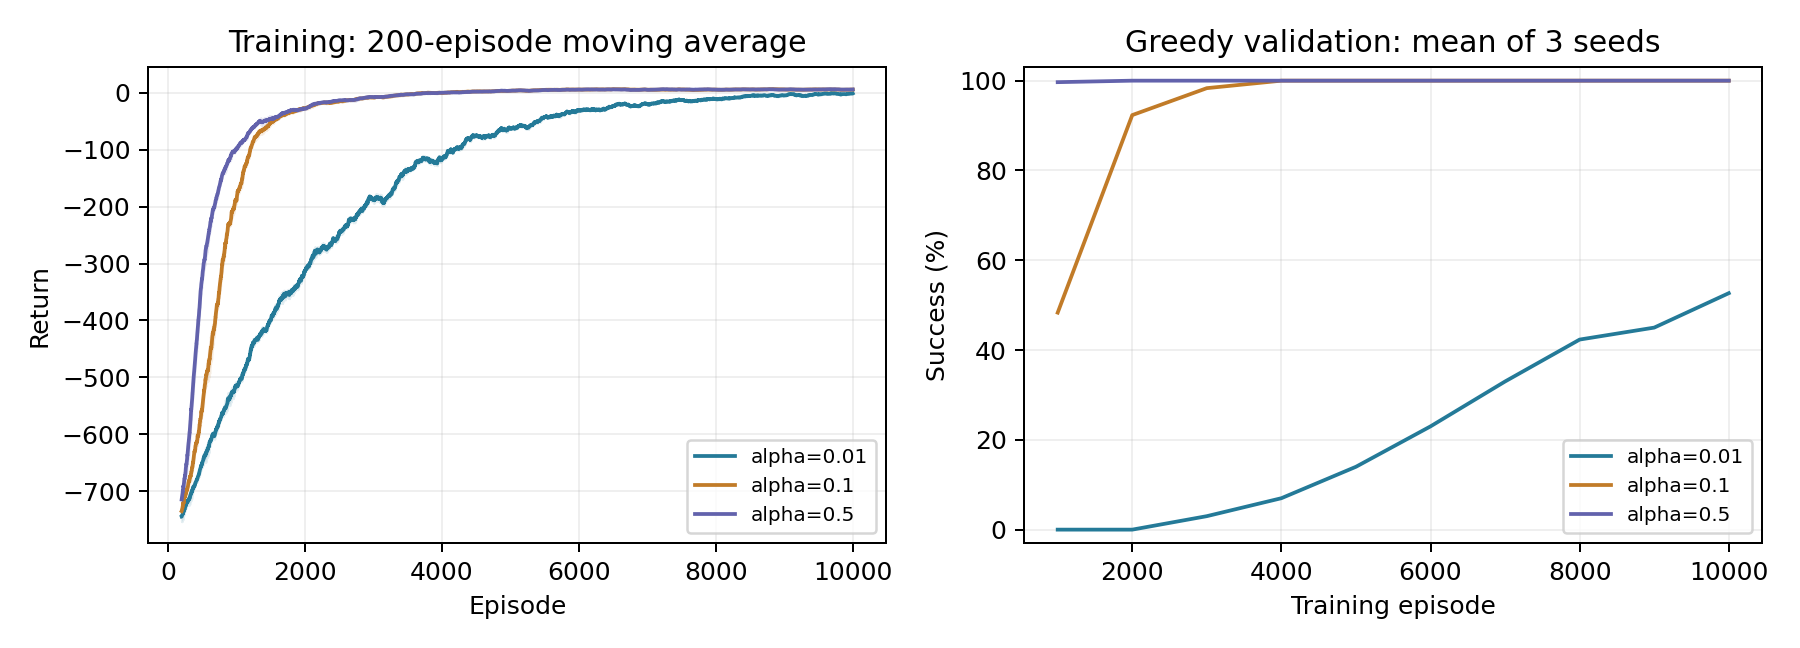

In [3]:
from IPython.display import display, Image
display(Image(filename="results/learning_curves.png"))

In [4]:
print("Selected alpha:", summary["selected_alpha"])
for name in ["test_random", "test_trained"]:
    print(name, summary[name])
q = np.load("results/q_table.npy")
print("Saved Q-table shape:", q.shape)
assert q.shape == (500, 6)
assert np.isfinite(q).all()

Selected alpha: 0.5
test_random {'mean_return': -764.49, 'success_rate': 0.03666666666666667, 'mean_steps': 196.82, 'episodes': 300}
test_trained {'mean_return': 7.973333333333334, 'success_rate': 1.0, 'mean_steps': 13.026666666666667, 'episodes': 300}
Saved Q-table shape: (500, 6)


## Successful demonstration
The GIF uses reset seed 2026. Yellow taxi: empty; green taxi: passenger on board. This is one illustrative episode; the test metrics summarize 300 episodes.

{'seed': 2026, 'return': 14, 'steps': 7, 'success': True}


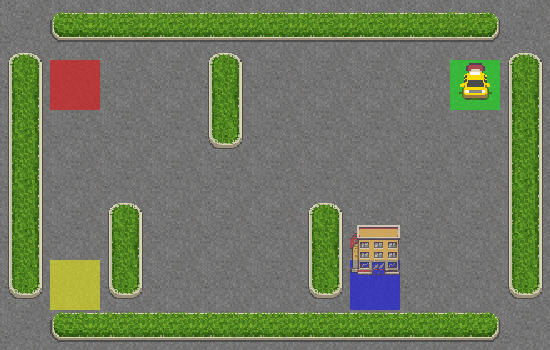

In [5]:
display(Image(filename="results/trained_agent.gif"))
print(summary["demo"])

## Interpretation
Compare training return with greedy validation: exploration can still cause penalties even after the greedy policy works well. The small discrete environment suits a Q-table; a continuous or large state space would require a different representation. See technical_report.pdf for the measured comparison and limitations.

Reference: https://gymnasium.farama.org/v1.2.3/environments/toy_text/taxi/